<a href="https://colab.research.google.com/github/rxphaelbihag/DS171-Intro-to-Supervised-Machine-Learning/blob/main/Multiclass%20Classification%20using%20OVR%20Strategy%20on%20IRIS%20dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory Exercise 6: One-versus-All Multi-class Classification Logistic Regression on IRIS Dataset

Student No.: 2024-05203

Name: Raphael Khandie B. Bihag

Section: DS171 (N-1L)

In [1]:
# Importing the libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Instructions:

*   Read and follow the given instructions.
*   A step-by-step process is given in each cell. Implement the required tasks.
*   For the synthesis questions, write your answers in the next cell. Your answers should be only 2-3 sentences.



Fetch and load the dataset (strictly use the Google Colaboratory approach)

Note: The `iris.csv` is loaded at temporary runtime for this activity.

In [4]:
dataset = pd.read_csv('/content/iris.csv') # Modify this part
dataset.describe()

,sepal.length,sepal.width,petal.length,petal.width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Splitting the dataset into the Training set and Test set :

In [6]:
# Splitting the dataset into the Training set and Test set
X = dataset.iloc[:, [0,1,2,3]].values
y = dataset.iloc[:, 4].values

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

Feature Scaling:


In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

One-vs-All Implementation:

The LogisticRegression class has its parameter `multi_class='deprecated'`. Thus, the class `multiclass.OneVsRestClassifier` is best used here.

In [11]:
# Fitting Logistic Regression with OVR Multi-Class Classifier to the Training set

# Your Source Code Here
# Add a line-by-line comment in this source code

# --- Answer ---
# import the required libraries
from sklearn.linear_model import LogisticRegression # for the estimator
from sklearn.multiclass import OneVsRestClassifier # for the OVR wrapper

# Instantiate the estimator for the OVR
estmtr = LogisticRegression(solver='liblinear', random_state=42)

# Instantiate the OVR classifier
classifier = OneVsRestClassifier(estmtr)

# Fit the model on the training data
classifier.fit(X_train, y_train)

OneVsRestClassifier(estimator=LogisticRegression(random_state=42,
                                                 solver='liblinear'))

Predicting the Test set results :

In [12]:
# Predicting the Test set results
y_pred = classifier.predict(X_test)
# Predict probabilities
probs_y=classifier.predict_proba(X_test)
# Print results
probs_y = np.round(probs_y, 2)
res = "{:<10} | {:<10} | {:<10} | {:<13} | {:<5}".format("y_test", "y_pred", "Setosa(%)", "Versicolor(%)", "Virginica(%)\n")
res += "-"*65+"\n"
res += "\n".join("{:<10} | {:<10} | {:<10} | {:<13} | {:<10}".format(x, y, a, b, c) for x, y, a, b, c in zip(y_test, y_pred, probs_y[:,0], probs_y[:,1], probs_y[:,2]))
res += "\n"+"-"*65+"\n"
print(res)

y_test     | y_pred     | Setosa(%)  | Versicolor(%) | Virginica(%)
-----------------------------------------------------------------
Virginica  | Virginica  | 0.0        | 0.22          | 0.78      
Versicolor | Versicolor | 0.02       | 0.89          | 0.09      
Setosa     | Setosa     | 0.98       | 0.02          | 0.0       
Virginica  | Virginica  | 0.0        | 0.34          | 0.66      
Setosa     | Setosa     | 0.88       | 0.12          | 0.0       
Virginica  | Virginica  | 0.0        | 0.1           | 0.89      
Setosa     | Setosa     | 0.91       | 0.09          | 0.0       
Versicolor | Virginica  | 0.04       | 0.38          | 0.58      
Versicolor | Versicolor | 0.01       | 0.55          | 0.44      
Versicolor | Versicolor | 0.09       | 0.66          | 0.26      
Virginica  | Versicolor | 0.01       | 0.54          | 0.46      
Versicolor | Virginica  | 0.1        | 0.33          | 0.57      
Versicolor | Versicolor | 0.05       | 0.67          | 0.29      
Versicol

## **Your** **Tasks**


1.   Modify the source code and apply the OVR Multi-class Classification.
2.   Create and plot the Confusion Matrix.
3.   Calculate the overall test accuracy.
4.   Calculate the evaluation metrics (precision, recall, and F1-score).



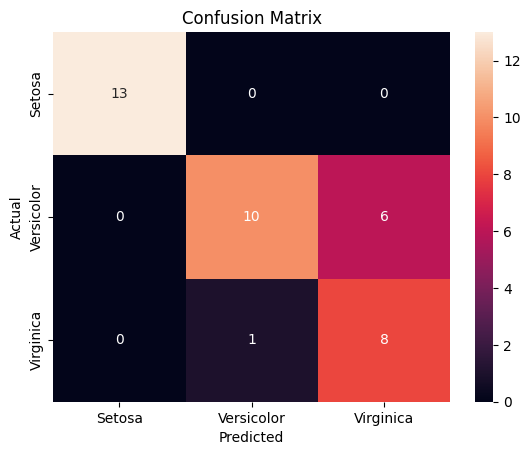

In [13]:
# import the required libraries for the plotting
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics # metrics class from sklearn

# Confusion Matrix
conf_matrix = metrics.confusion_matrix(y_test, y_pred)

# plot confusion matrix using seaborn's heatmap
classes = classifier.classes_
sns.heatmap(conf_matrix, annot=True, xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [14]:
# Accuracy for Test Data
score = classifier.score(X_test, y_test)
print("Model's Score:", score)

Model's Score: 0.8157894736842105


In [15]:
# Calculate Evaluation Metrics
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        13
  Versicolor       0.91      0.62      0.74        16
   Virginica       0.57      0.89      0.70         9

    accuracy                           0.82        38
   macro avg       0.83      0.84      0.81        38
weighted avg       0.86      0.82      0.82        38



### **Analytical Questions**


*   Q1: How does the One-versus-All (OvR) strategy transform a 3-class problem into binary logistic regression classifiers? How does the model resolve the final predicted class label when multiple classifiers yield probability scores?

>

*   Q2: Examining the prediction probabilities and confusion matrix, why does the One-versus-All logistic regression achieve perfect classification accuracy on *Setosa*, whereas *Versicolor* and *Virginica* share a slight probability overlap near the decision boundary?



**Answers**

Q1:
> The OVR strategy transforms the problem by training 3 separate binary logistic regression classifiers such that each classifier is modeled on one class against all the other classes. The model resolves the final predicted class by picking the class of the classifier yielding the highest probability score.

Q2:
> The reason why the OVR strategy was able to achieve a perfect classification accuracy on Setosa is because the class of Setosa has features that form an isolated region in the feature space allowing the strategy to establish a clear and linear separation against the two other classes. Versicolor and Virginica, on the other hand, share overlapping feature distributions with no clear physical separation. Because of this, a linear boundary cannot perfectly separate the two resulting to competing probability scores for data points situated in the transition zone.

##**Submission**:
Save all your code and analysis answers in a single Jupyter notebook. Make sure that your notebook has the student number, full name, and section commented in the first cell. Export the notebook with complete executed outputs and save it following the filename format “surname_section_labexe6.ipynb”.
- Submit your notebook to the LMS submission bin on or before the specified deadline.
- Late submission will be subject to a point deduction (10% per day, up to a 3-day maximum delay).
- Submissions that do not comply with the stated requirements and guidelines will be graded 0. Refer to the course syllabus for details on the source code evaluation rubric.